# Customer Churn Prediction

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
)

sns.set_theme(style="whitegrid", palette="Set2")
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 120)
print("Libraries loaded.")


Libraries loaded.


## 1. Load the dataset

In [2]:
DATA_PATH = r"archive (1)/WA_Fn-UseC_-Telco-Customer-Churn.csv"
df = pd.read_csv(DATA_PATH)

print("Shape:", df.shape)
print("\nColumns:")
print(list(df.columns))
print("\nSample rows:")
print(df.head())
print("\nData types:")
print(df.dtypes)


Shape: (7043, 21)

Columns:
['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn']

Sample rows:
   customerID  gender  SeniorCitizen Partner Dependents  tenure PhoneService     MultipleLines InternetService  \
0  7590-VHVEG  Female              0     Yes         No       1           No  No phone service             DSL   
1  5575-GNVDE    Male              0      No         No      34          Yes                No             DSL   
2  3668-QPYBK    Male              0      No         No       2          Yes                No             DSL   
3  7795-CFOCW    Male              0      No         No      45           No  No phone service             DSL   
4  9237-HQITU  Female              0      No         No       2 

## 2. Data quality


In [3]:
print("Missing values before cleaning:")
print(df.isnull().sum())

blank_charges = df["TotalCharges"].astype(str).str.strip().eq("").sum()
print(f"\nBlank TotalCharges values: {blank_charges}")

df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
print("Rows with non-numeric TotalCharges (tenure should be 0):")
print(df.loc[df["TotalCharges"].isna(), ["tenure", "MonthlyCharges", "TotalCharges"]].head(10))

df["TotalCharges"] = df["TotalCharges"].fillna(0)
df = df.drop(columns=["customerID"])

print("\nMissing values after cleaning:")
print(df.isnull().sum().sum())
print(df.describe().round(2))


Missing values before cleaning:
customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

Blank TotalCharges values: 11
Rows with non-numeric TotalCharges (tenure should be 0):
      tenure  MonthlyCharges  TotalCharges
488        0           52.55           NaN
753        0           20.25           NaN
936        0           80.85           NaN
1082       0           25.75           NaN
1340       0           56.05           NaN
3331       0           19.85           NaN
3826       0           25.35           NaN
4380       0           20.00           NaN
5218       0      

## 3. Churn indicators


Customers: 7043
Churn
No     5174
Yes    1869

Overall churn rate: 26.54%
The classes are imbalanced: most customers stay. Accuracy alone would look strong for a model that always predicts 'No'.


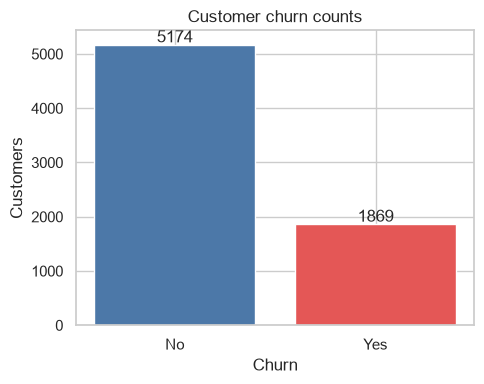

In [4]:
df["ChurnFlag"] = (df["Churn"] == "Yes").astype(int)
overall_rate = df["ChurnFlag"].mean()
print(f"Customers: {len(df)}")
print(df["Churn"].value_counts().to_string())
print(f"\nOverall churn rate: {overall_rate:.2%}")
print("The classes are imbalanced: most customers stay. Accuracy alone would look strong for a model that always predicts 'No'.")

fig, ax = plt.subplots(figsize=(5, 4))
counts = df["Churn"].value_counts()
bars = ax.bar(counts.index, counts.values, color=["#4C78A8", "#E45756"])
ax.set_title("Customer churn counts")
ax.set_xlabel("Churn")
ax.set_ylabel("Customers")
for bar, value in zip(bars, counts.values):
    ax.text(bar.get_x() + bar.get_width() / 2, value + 40, str(value), ha="center")
plt.tight_layout()


In [5]:
def churn_rate_by(frame, column):
    table = (
        frame.groupby(column, observed=True)["ChurnFlag"]
        .agg(customers="count", churned="sum", churn_rate="mean")
        .sort_values("churn_rate", ascending=False)
    )
    table["churn_rate_pct"] = (table["churn_rate"] * 100).round(2)
    return table

categorical_indicators = [
    "Contract",
    "InternetService",
    "PaymentMethod",
    "TechSupport",
    "OnlineSecurity",
    "PaperlessBilling",
    "SeniorCitizen",
    "Partner",
    "Dependents",
    "gender",
]

print(f"Overall churn rate: {overall_rate * 100:.2f}%\n")
indicator_rows = []
for column in categorical_indicators:
    table = churn_rate_by(df, column)
    print(f"=== {column} ===")
    print(table[["customers", "churned", "churn_rate_pct"]].to_string())
    print()
    best = table.index[0]
    indicator_rows.append(
        {
            "feature": column,
            "highest_churn_group": str(best),
            "churn_rate_pct": table.iloc[0]["churn_rate_pct"],
            "customers": int(table.iloc[0]["customers"]),
        }
    )

indicator_summary = pd.DataFrame(indicator_rows).sort_values("churn_rate_pct", ascending=False)
print("Groups with the highest churn rate in each feature:")
print(indicator_summary.to_string(index=False))


Overall churn rate: 26.54%

=== Contract ===
                customers  churned  churn_rate_pct
Contract                                          
Month-to-month       3875     1655           42.71
One year             1473      166           11.27
Two year             1695       48            2.83

=== InternetService ===
                 customers  churned  churn_rate_pct
InternetService                                    
Fiber optic           3096     1297           41.89
DSL                   2421      459           18.96
No                    1526      113            7.40

=== PaymentMethod ===
                           customers  churned  churn_rate_pct
PaymentMethod                                                
Electronic check                2365     1071           45.29
Mailed check                    1612      308           19.11
Bank transfer (automatic)       1544      258           16.71
Credit card (automatic)         1522      232           15.24

=== TechSupport ===

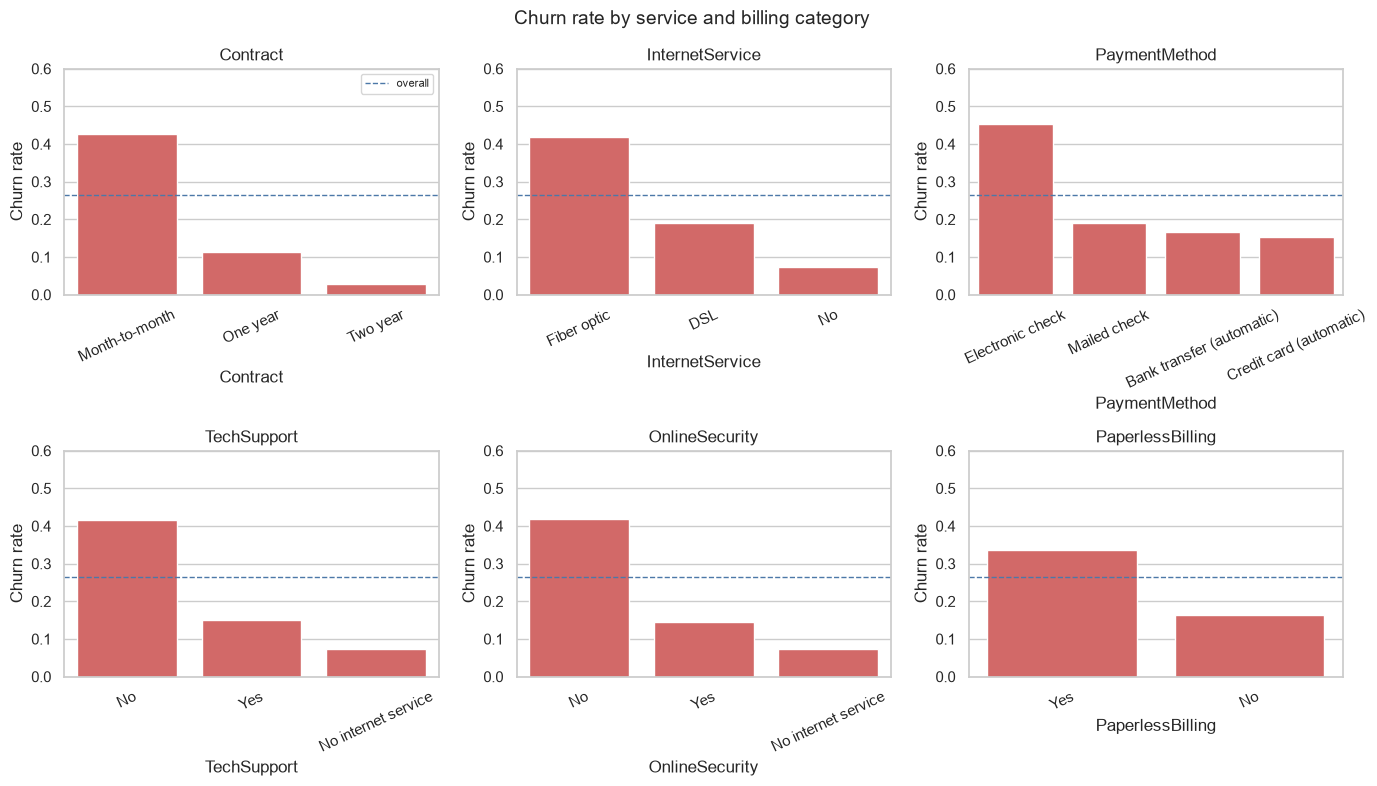

In [6]:
plot_features = ["Contract", "InternetService", "PaymentMethod", "TechSupport", "OnlineSecurity", "PaperlessBilling"]
fig, axes = plt.subplots(2, 3, figsize=(14, 8))
for ax, column in zip(axes.ravel(), plot_features):
    table = churn_rate_by(df, column).reset_index()
    sns.barplot(data=table, x=column, y="churn_rate", ax=ax, color="#E45756")
    ax.axhline(overall_rate, color="#4C78A8", linestyle="--", linewidth=1, label="overall")
    ax.set_ylim(0, 0.6)
    ax.set_ylabel("Churn rate")
    ax.set_title(column)
    ax.tick_params(axis="x", rotation=25)
axes[0, 0].legend(loc="upper right", fontsize=8)
fig.suptitle("Churn rate by service and billing category", fontsize=14)
plt.tight_layout()


=== Tenure (months) ===
            customers  churned  churn_rate_pct
tenure_bin                                    
0-6              1481      784           52.94
7-12              705      253           35.89
13-24            1024      294           28.71
25-48            1594      325           20.39
49-72            2239      213            9.51

=== Monthly charges ===
             customers  churned  churn_rate_pct
monthly_bin                                    
70-90             1844      697           37.80
90-120            1739      570           32.78
35-70             1725      413           23.94
0-35              1735      189           10.89


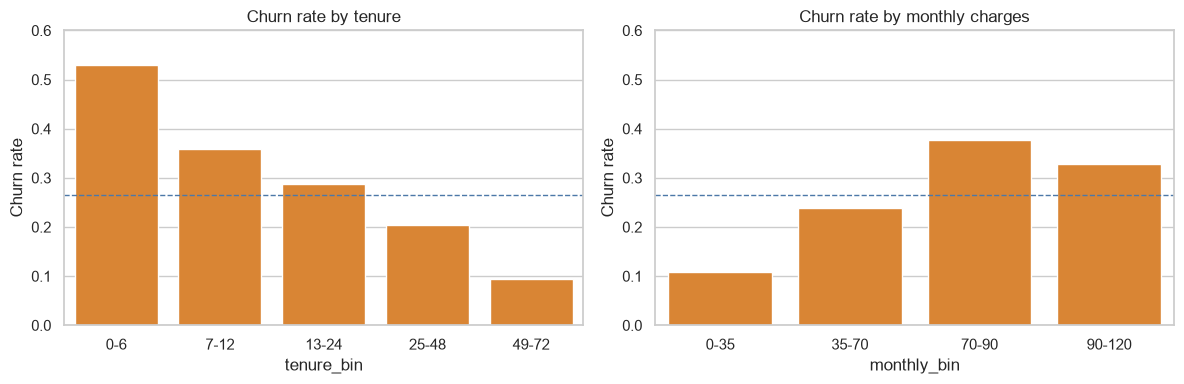

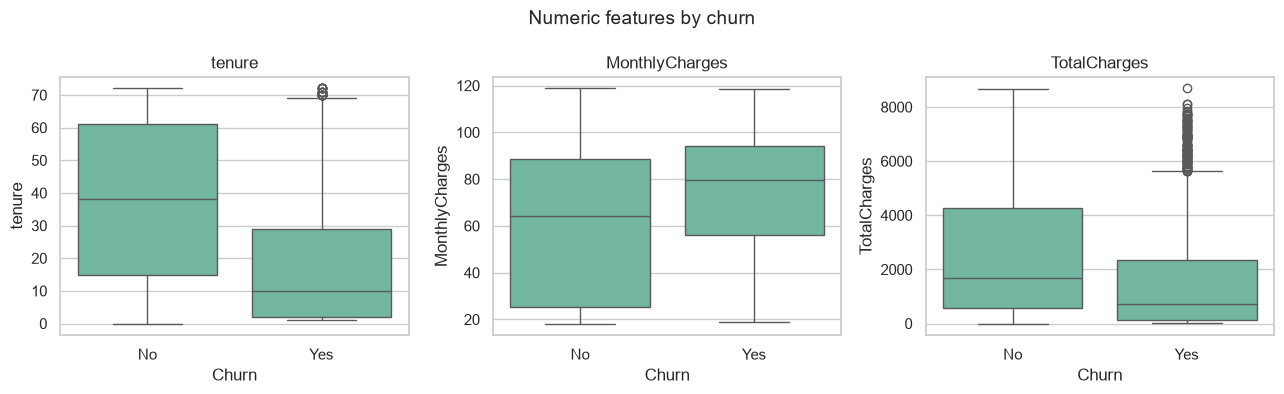

In [7]:
df["tenure_bin"] = pd.cut(
    df["tenure"],
    bins=[-1, 6, 12, 24, 48, 72],
    labels=["0-6", "7-12", "13-24", "25-48", "49-72"],
)
df["monthly_bin"] = pd.cut(
    df["MonthlyCharges"],
    bins=[0, 35, 70, 90, 120],
    labels=["0-35", "35-70", "70-90", "90-120"],
)

print("=== Tenure (months) ===")
print(churn_rate_by(df, "tenure_bin")[["customers", "churned", "churn_rate_pct"]].to_string())
print("\n=== Monthly charges ===")
print(churn_rate_by(df, "monthly_bin")[["customers", "churned", "churn_rate_pct"]].to_string())

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, column, title in zip(
    axes,
    ["tenure_bin", "monthly_bin"],
    ["Churn rate by tenure", "Churn rate by monthly charges"],
):
    table = churn_rate_by(df, column).reset_index()
    sns.barplot(data=table, x=column, y="churn_rate", ax=ax, color="#F58518")
    ax.axhline(overall_rate, color="#4C78A8", linestyle="--", linewidth=1)
    ax.set_ylim(0, 0.6)
    ax.set_xlabel(column)
    ax.set_ylabel("Churn rate")
    ax.set_title(title)
plt.tight_layout()

fig, axes = plt.subplots(1, 3, figsize=(13, 4))
for ax, column in zip(axes, ["tenure", "MonthlyCharges", "TotalCharges"]):
    sns.boxplot(data=df, x="Churn", y=column, ax=ax)
    ax.set_title(column)
fig.suptitle("Numeric features by churn", fontsize=14)
plt.tight_layout()


## 4. Feature engineering and encoding

In [8]:
addon_cols = [
    "OnlineSecurity",
    "OnlineBackup",
    "DeviceProtection",
    "TechSupport",
    "StreamingTV",
    "StreamingMovies",
]
df["addon_count"] = (df[addon_cols] == "Yes").sum(axis=1)
df["avg_charge_per_tenure"] = np.where(
    df["tenure"] > 0,
    df["TotalCharges"] / df["tenure"],
    df["MonthlyCharges"],
)

model_df = df.drop(columns=["Churn", "tenure_bin", "monthly_bin"])
y = model_df.pop("ChurnFlag")

numeric_features = [
    "SeniorCitizen",
    "tenure",
    "MonthlyCharges",
    "TotalCharges",
    "addon_count",
    "avg_charge_per_tenure",
]
categorical_features = [col for col in model_df.columns if col not in numeric_features]

print("Numeric features:", numeric_features)
print("Categorical features:", categorical_features)
print("\nAddon count vs churn rate:")
print(churn_rate_by(df, "addon_count")[["customers", "churn_rate_pct"]].to_string())
print("\nFeature preview:")
print(model_df[numeric_features + categorical_features[:4]].head())


Numeric features: ['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges', 'addon_count', 'avg_charge_per_tenure']
Categorical features: ['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']

Addon count vs churn rate:
             customers  churn_rate_pct
addon_count                           
1                  966           45.76
2                 1033           35.82
3                 1118           27.37
4                  852           22.30
0                 2219           21.41
5                  571           12.43
6                  284            5.28

Feature preview:
   SeniorCitizen  tenure  MonthlyCharges  TotalCharges  addon_count  avg_charge_per_tenure  gender Partner Dependents  \
0              0       1           29.85         29.85            1              29.850000  Female  

## 5. Train classification models

In [9]:
X_train, X_test, y_train, y_test = train_test_split(
    model_df,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y,
)

print("Train size:", X_train.shape[0], " Test size:", X_test.shape[0])
print(f"Train churn rate: {y_train.mean():.2%}  Test churn rate: {y_test.mean():.2%}")

preprocess = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numeric_features),
        (
            "cat",
            OneHotEncoder(drop="if_binary", handle_unknown="ignore", sparse_output=False),
            categorical_features,
        ),
    ]
)

models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, class_weight="balanced", random_state=42),
    "Decision Tree": DecisionTreeClassifier(max_depth=6, class_weight="balanced", random_state=42),
    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        max_depth=12,
        min_samples_leaf=5,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1,
    ),
    "Gradient Boosting": GradientBoostingClassifier(
        n_estimators=150,
        learning_rate=0.08,
        max_depth=3,
        random_state=42,
    ),
}

fitted = {}
for name, estimator in models.items():
    pipeline = Pipeline([("preprocess", preprocess), ("model", estimator)])
    pipeline.fit(X_train, y_train)
    fitted[name] = pipeline
    print(f"Trained {name}")


Train size: 5634  Test size: 1409
Train churn rate: 26.54%  Test churn rate: 26.54%
Trained Logistic Regression
Trained Decision Tree
Trained Random Forest
Trained Gradient Boosting


## 6. Evaluation: precision, recall, and F1-score

In [10]:
def churn_metrics(y_true, y_pred):
    return {
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred, pos_label=1, zero_division=0),
        "Recall": recall_score(y_true, y_pred, pos_label=1, zero_division=0),
        "F1-score": f1_score(y_true, y_pred, pos_label=1, zero_division=0),
    }

rows = []
predictions = {}
for name, pipeline in fitted.items():
    pred = pipeline.predict(X_test)
    predictions[name] = pred
    row = {"Model": name}
    row.update(churn_metrics(y_test, pred))
    rows.append(row)

rows.append({"Model": "Baseline: always stay", **churn_metrics(y_test, np.zeros_like(y_test))})
rows.append({"Model": "Baseline: always churn", **churn_metrics(y_test, np.ones_like(y_test))})

results = pd.DataFrame(rows).sort_values("F1-score", ascending=False)
results_display = results.copy()
for col in ["Accuracy", "Precision", "Recall", "F1-score"]:
    results_display[col] = results_display[col].map(lambda v: f"{v:.4f}")

print("Churn-class metrics on the held-out test set:")
print(results_display.to_string(index=False))

best_name = results.loc[~results["Model"].str.startswith("Baseline"), "F1-score"].idxmax()
best_name = results.loc[best_name, "Model"]
print(f"\nBest model by churn F1-score: {best_name}")
print("\nClassification report:")
print(classification_report(y_test, predictions[best_name], target_names=["Stay", "Churn"], digits=4))


Churn-class metrics on the held-out test set:
                 Model Accuracy Precision Recall F1-score
         Random Forest   0.7615    0.5357 0.7620   0.6291
   Logistic Regression   0.7381    0.5043 0.7834   0.6136
         Decision Tree   0.7317    0.4966 0.7861   0.6087
     Gradient Boosting   0.8006    0.6632 0.5053   0.5736
Baseline: always churn   0.2654    0.2654 1.0000   0.4195
 Baseline: always stay   0.7346    0.0000 0.0000   0.0000

Best model by churn F1-score: Random Forest

Classification report:
              precision    recall  f1-score   support

        Stay     0.8985    0.7614    0.8243      1035
       Churn     0.5357    0.7620    0.6291       374

    accuracy                         0.7615      1409
   macro avg     0.7171    0.7617    0.7267      1409
weighted avg     0.8022    0.7615    0.7725      1409



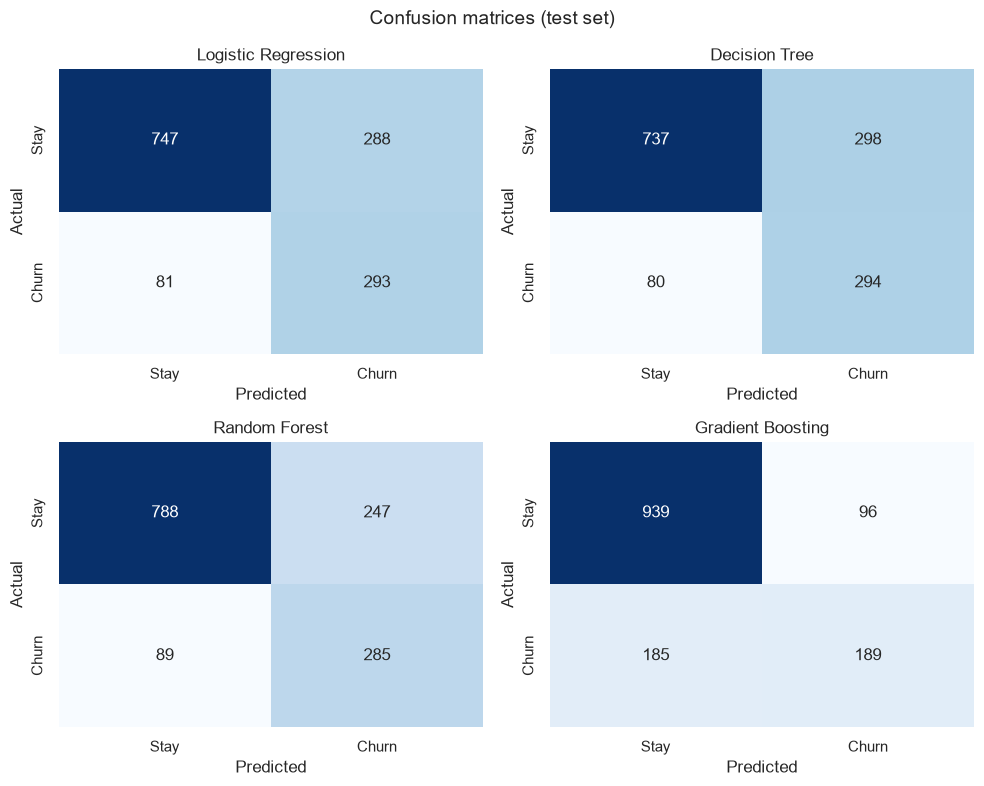

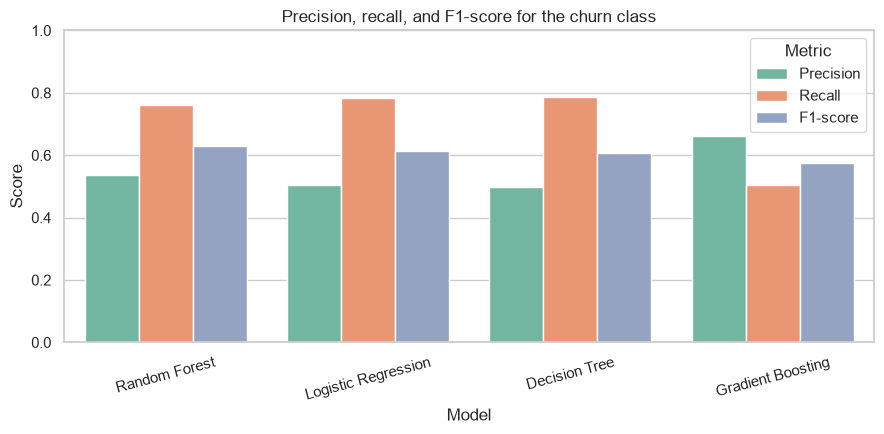

In [11]:
model_names = list(fitted.keys())
fig, axes = plt.subplots(2, 2, figsize=(10, 8))
for ax, name in zip(axes.ravel(), model_names):
    matrix = confusion_matrix(y_test, predictions[name])
    sns.heatmap(
        matrix,
        annot=True,
        fmt="d",
        cmap="Blues",
        cbar=False,
        ax=ax,
        xticklabels=["Stay", "Churn"],
        yticklabels=["Stay", "Churn"],
    )
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")
    ax.set_title(name)
fig.suptitle("Confusion matrices (test set)", fontsize=14)
plt.tight_layout()

plot_df = results[~results["Model"].str.startswith("Baseline")].melt(
    id_vars="Model",
    value_vars=["Precision", "Recall", "F1-score"],
    var_name="Metric",
    value_name="Score",
)
fig, ax = plt.subplots(figsize=(9, 4.5))
sns.barplot(data=plot_df, x="Model", y="Score", hue="Metric", ax=ax)
ax.set_ylim(0, 1)
ax.set_title("Precision, recall, and F1-score for the churn class")
ax.tick_params(axis="x", rotation=15)
plt.tight_layout()


## 7. What the models use


Top 15 random forest features:
                            feature  importance
                        num__tenure    0.123521
       cat__Contract_Month-to-month    0.120253
                  num__TotalCharges    0.094105
             cat__Contract_Two year    0.071739
         num__avg_charge_per_tenure    0.065283
                num__MonthlyCharges    0.063525
             cat__OnlineSecurity_No    0.060106
                cat__TechSupport_No    0.044506
   cat__InternetService_Fiber optic    0.041937
cat__PaymentMethod_Electronic check    0.037659
             cat__Contract_One year    0.022120
           cat__InternetService_DSL    0.016602
                   num__addon_count    0.016184
            cat__OnlineSecurity_Yes    0.014559
               cat__OnlineBackup_No    0.014429

Largest logistic regression coefficients:
                                  feature  coefficient
                              num__tenure    -1.154520
                   cat__Contract_Two year    -0.

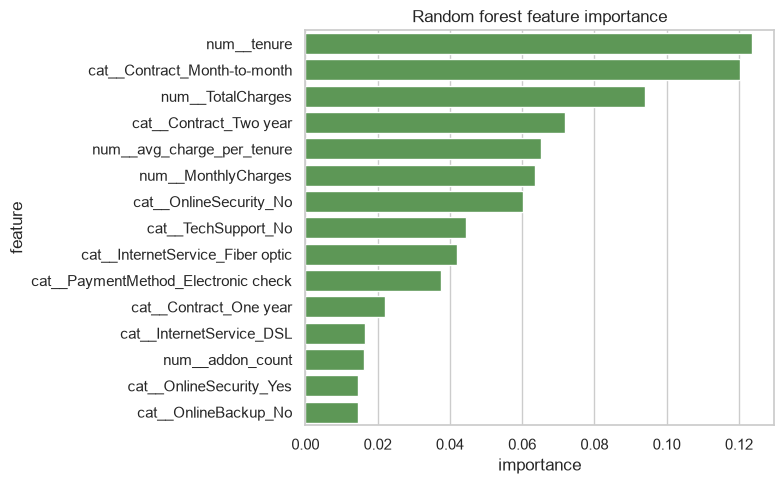

In [12]:
rf_pipeline = fitted["Random Forest"]
feature_names = rf_pipeline.named_steps["preprocess"].get_feature_names_out()
importances = rf_pipeline.named_steps["model"].feature_importances_
importance_df = (
    pd.DataFrame({"feature": feature_names, "importance": importances})
    .sort_values("importance", ascending=False)
    .head(15)
)
print("Top 15 random forest features:")
print(importance_df.to_string(index=False))

fig, ax = plt.subplots(figsize=(8, 5))
sns.barplot(data=importance_df, y="feature", x="importance", ax=ax, color="#54A24B")
ax.set_title("Random forest feature importance")
plt.tight_layout()

lr_pipeline = fitted["Logistic Regression"]
coefficients = lr_pipeline.named_steps["model"].coef_[0]
coef_df = (
    pd.DataFrame({"feature": feature_names, "coefficient": coefficients})
    .assign(abs_coef=lambda frame: frame["coefficient"].abs())
    .sort_values("abs_coef", ascending=False)
    .head(12)
    .drop(columns="abs_coef")
)
print("\nLargest logistic regression coefficients:")
print(coef_df.to_string(index=False))


## 8. Findings

Overall churn rate: **26.54%** (1869 of 7043 customers).

Highest-risk groups:
- **PaymentMethod = Electronic check**: 45.29% churn (2365 customers)
- **Contract = Month-to-month**: 42.71% churn (3875 customers)
- **InternetService = Fiber optic**: 41.89% churn (3096 customers)
- **OnlineSecurity = No**: 41.77% churn (3498 customers)
- **SeniorCitizen = 1**: 41.68% churn (1142 customers)

Short tenure (especially the first six months) and higher monthly charges also line up with higher churn. Gender barely separates the two classes.

On the test set, **Random Forest** has the highest churn-class F1-score (0.6291), with precision 0.5357 and recall 0.7620.

For retention, the useful operating point is recall: a campaign should catch customers who will actually leave. Precision still matters, because offers sent to loyal customers waste budget. The balanced logistic regression and tree models trade some precision for higher recall. Gradient boosting is usually more precise and less complete on the churn class because it was not class-weighted.

Retention priority suggested by the indicators: month-to-month fiber customers who pay by electronic check, have low tenure, and do not use tech support or online security.
